# Lecture 7 — Class Exercise
## Part-to-Whole: Hierarchical Visualization

> **Push to:** `week07/lecture07_exercise.ipynb`


In [1]:

import pandas as pd
import plotly.express as px
import numpy as np
from pathlib import Path

# Find the dataset
possible_paths = [
    Path('../data/global_energy_mix.csv'),
    Path('global_energy_mix.csv'),
    Path('/mnt/data/global_energy_mix.csv')
]

file_path = next((p for p in possible_paths if p.exists()), None)

if file_path is None:
    raise FileNotFoundError("CSV file not found. Check its location.")

# Load dataset
df = pd.read_csv(file_path)

# Source type mapping
source_category = {
    'Coal': 'Fossil',
    'Oil': 'Fossil',
    'Natural Gas': 'Fossil',
    'Nuclear': 'Low-carbon',
    'Hydro': 'Low-carbon',
    'Wind': 'Renewable',
    'Solar': 'Renewable',
    'Other Renewables': 'Renewable'
}

df['Source_Type'] = df['Source'].map(source_category)

print(f"Loaded: {len(df)} rows")
print(df.head(10))



Loaded: 103 rows
         Country         Region            Source  Share_pct     TWh  \
0  United States  North America              Coal         10  1015.0   
1  United States  North America               Oil         35  3220.0   
2  United States  North America       Natural Gas         34  3083.0   
3  United States  North America           Nuclear          9   798.0   
4  United States  North America             Hydro          3   339.0   
5  United States  North America              Wind          4   413.0   
6  United States  North America             Solar          3   325.0   
7  United States  North America  Other Renewables          2   229.0   
8          China           Asia              Coal         58  6929.1   
9          China           Asia               Oil         18  1620.0   

  Source_Type  
0      Fossil  
1      Fossil  
2      Fossil  
3  Low-carbon  
4  Low-carbon  
5   Renewable  
6   Renewable  
7   Renewable  
8      Fossil  
9      Fossil  


## Task 1 — Treemap: fossil fuel dependency by country

**What to build:** A treemap showing **fossil fuel TWh only**, broken down by Region → Country → Source (Coal / Oil / Natural Gas).

**Requirements:**
- Filter to fossil sources only before plotting
- Use `path=['Region', 'Country', 'Source']` for the hierarchy
- Colour encodes the fossil source type (Coal / Oil / Natural Gas) with a CVD-safe palette
- Show TWh values in labels — no percentages
- Grey out parent nodes (Region and Country level)
- Insight title naming which region or country is most fossil-dependent

> 💡 `df.loc[df['Source_Type'] == 'Fossil']`


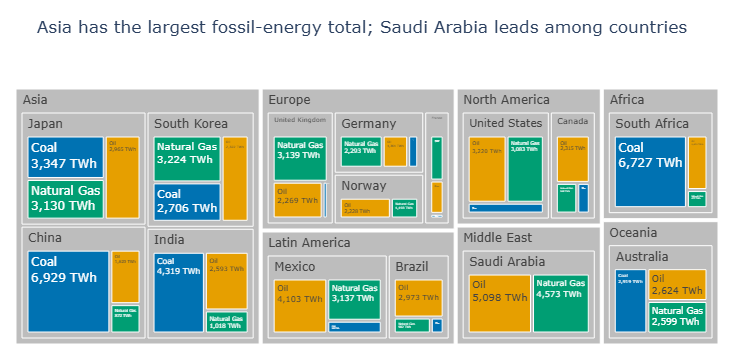

In [2]:
# Task 1
# YOUR CODE HERE
# Task 1 — fossil-fuel treemap
df_fossil = df.loc[df['Source_Type'] == 'Fossil'].copy()

# CVD-safe palette (Okabe–Ito-inspired); Coal blue is reused in Task 3
fossil_colors = {'Coal': '#0072B2', 'Oil': '#E69F00', 'Natural Gas': '#009E73'}

fig1 = px.treemap(
    df_fossil,
    path=['Region', 'Country', 'Source'],
    values='TWh',
    color='Source',
    color_discrete_map=fossil_colors,
    title='Asia has the largest fossil-energy total; Saudi Arabia leads among countries'
)
# Grey parent nodes (Region and Country); colour only the Source leaves
fig1.update_traces(
    marker=dict(colors=[
        '#BDBDBD' if str(node_id).count('/') < 2 else fossil_colors.get(str(node_id).split('/')[-1], '#BDBDBD')
        for node_id in fig1.data[0].ids
    ]),
    texttemplate='%{label}<br>%{value:,.0f} TWh',
    hovertemplate='%{label}<br>%{value:,.1f} TWh<extra></extra>'
)
fig1.update_layout(margin=dict(t=65, l=10, r=10, b=10))
fig1.show()


## Task 2 — Treemap vs bar: low-carbon energy by country

**What to build:** Build **both** a treemap and a horizontal bar chart showing total low-carbon TWh (Nuclear + Hydro) per country. Then answer the question in a markdown cell below.

**Requirements:**
- Filter to `Source_Type == 'Low-carbon'` and aggregate TWh by country
- Treemap: single-level `path=['All', 'Country']` with a dummy root node labelled `'Low-carbon'`
- Bar chart: sorted by TWh, horizontal orientation, CVD-safe colour
- Both charts show TWh values, not percentages
- Insight title on the bar chart naming the leading country

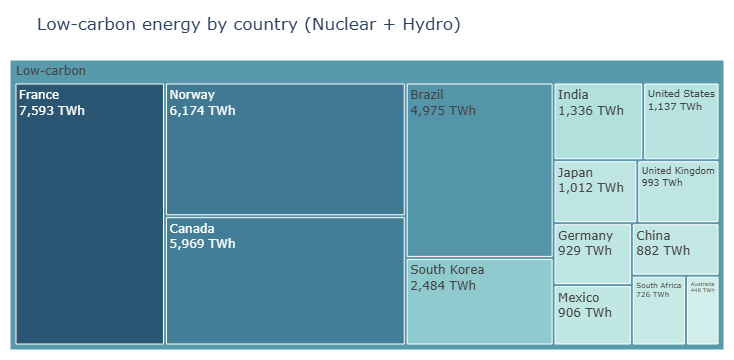

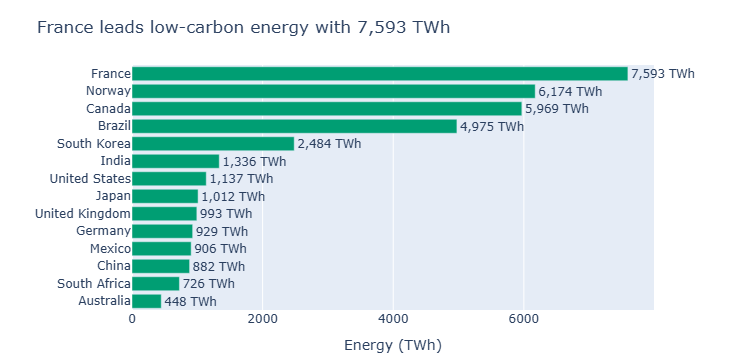

In [3]:
# Task 2 — charts
# YOUR CODE HERE
# Task 2 — low-carbon treemap and horizontal ranking bar chart
df_low_carbon = df.loc[df['Source_Type'] == 'Low-carbon']
low_carbon_by_country = (
    df_low_carbon.groupby('Country', as_index=False)['TWh'].sum()
    .sort_values('TWh', ascending=False)
)
low_carbon_by_country['All'] = 'Low-carbon'  # dummy root required for the hierarchy

fig2_tree = px.treemap(
    low_carbon_by_country,
    path=['All', 'Country'],
    values='TWh',
    color='TWh',
    color_continuous_scale='Teal',
    title='Low-carbon energy by country (Nuclear + Hydro)'
)
fig2_tree.update_traces(
    texttemplate='%{label}<br>%{value:,.0f} TWh',
    hovertemplate='%{label}<br>%{value:,.1f} TWh<extra></extra>'
)
fig2_tree.update_layout(coloraxis_showscale=False, margin=dict(t=60, l=10, r=10, b=10))
fig2_tree.show()

leader = low_carbon_by_country.iloc[0]
fig2_bar = px.bar(
    low_carbon_by_country.sort_values('TWh', ascending=True),
    x='TWh', y='Country', orientation='h',
    text='TWh',
    color_discrete_sequence=['#009E73'],
    title=f"{leader['Country']} leads low-carbon energy with {leader['TWh']:,.0f} TWh"
)
fig2_bar.update_traces(texttemplate='%{text:,.0f} TWh', textposition='outside', cliponaxis=False)
fig2_bar.update_layout(xaxis_title='Energy (TWh)', yaxis_title='', showlegend=False,
                       margin=dict(t=65, l=10, r=80, b=10))
fig2_bar.show()


### Task 2 — reflection

**Which chart tells the ranking story more clearly, and why?**

*YOUR ANSWER HERE*:-The horizontal bar chart tells the ranking story more clearly because all countries share the same zero baseline, so lengths are easy to compare and the countries can be read in sorted order. The treemap is better for seeing part-to-whole composition and the relative size of each country's contribution, but comparing similarly sized rectangles is less precise.

## Task 3 — 100% stacked bar: which region relies most on coal?

**What to build:** A horizontal 100% stacked bar chart showing, for each **Region**, how its fossil energy splits between Coal, Oil and Natural Gas. This is the **same data as your Task 1 treemap**, visualised a second way.

**Requirements:**
- Reuse `df_fossil` from Task 1; aggregate TWh by `Region` × `Source` and convert to **shares of each region's fossil total**
- Horizontal bars, regions **sorted by coal share** (highest at the top)
- Coal is the segment on the baseline (first in `category_orders`) and the **only coloured segment** — keep it the same colour as in Task 1; Oil and Natural Gas in two greys
- Percentage labels on the coal segments only
- Insight title naming the most coal-dependent region and its coal share

> 💡 `df.groupby('Region')['TWh'].transform('sum')` gives each row its region total

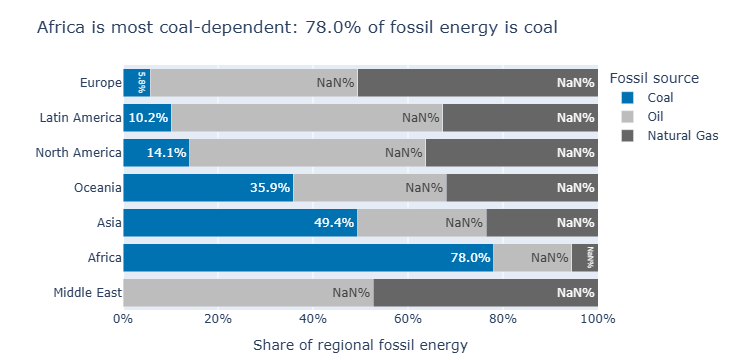

,Region,Share
0,Africa,78.0%
3,Asia,49.4%
17,Oceania,35.9%
14,North America,14.1%
9,Latin America,10.2%
6,Europe,5.8%


In [4]:
# Task 3
# YOUR CODE HERE
# Task 3 — regional fossil mix as 100% stacked horizontal bars
# Reuse df_fossil created in Task 1
regional_source = (
    df_fossil.groupby(['Region', 'Source'], as_index=False)['TWh'].sum()
)
regional_source['Region_Total'] = regional_source.groupby('Region')['TWh'].transform('sum')
regional_source['Share'] = regional_source['TWh'] / regional_source['Region_Total']
regional_source['Coal_Label'] = regional_source['Share'].where(regional_source['Source'] == 'Coal', np.nan)

coal_share = (regional_source.loc[regional_source['Source'] == 'Coal', ['Region', 'Share']]
              .sort_values('Share', ascending=False))
region_order = coal_share['Region'].tolist()
top_region = coal_share.iloc[0]

fig3 = px.bar(
    regional_source,
    x='Share', y='Region', color='Source',
    orientation='h', barmode='stack',
    category_orders={'Region': region_order, 'Source': ['Coal', 'Oil', 'Natural Gas']},
    color_discrete_map={'Coal': '#0072B2', 'Oil': '#BDBDBD', 'Natural Gas': '#666666'},
    text='Coal_Label',
    title=f"{top_region['Region']} is most coal-dependent: {top_region['Share']:.1%} of fossil energy is coal"
)
# Label only the Coal segment; Oil and Natural Gas remain unlabelled
fig3.update_traces(
    texttemplate='%{text:.1%}',
    textposition='inside',
    hovertemplate='%{y}<br>%{fullData.name}: %{x:.1%}<extra></extra>'
)
fig3.update_xaxes(tickformat='.0%', range=[0, 1], title='Share of regional fossil energy')
fig3.update_yaxes(title='', autorange='reversed')
fig3.update_layout(legend_title_text='Fossil source', margin=dict(t=65, l=10, r=10, b=10))
fig3.show()

# Optional numeric check of the regional coal shares
display(coal_share.assign(Share=coal_share['Share'].map(lambda x: f'{x:.1%}')))


### Task 3 — reflection

**Your Task 1 treemap and this stacked bar show the same fossil data. Name one question each chart answers that the other cannot.**

*YOUR ANSWER HERE*:-The treemap compares absolute energy consumption, while the stacked bar chart compares percentages and proportions.